In [1]:
import pandas as pd
from sklearn.metrics import r2_score
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv("combined_descriptors.csv")
df.columns
for c in df.columns:
    print(c)

path
xyz_name
ligand_type
inchi
SCF_energy
smiles
ligand_class
feather_path
SASA
SASA_Volume
%Vbur_atom_H1_radius_2.0
%Vbur_atom_H1_radius_2.5
%Vbur_atom_H1_radius_3.0
%Vbur_atom_H1_radius_3.5
%Vbur_atom_H1_radius_4.0
%Vbur_atom_H1_radius_4.5
%Vbur_atom_H1_radius_5.0
%Vbur_atom_H2_radius_2.0
%Vbur_atom_H2_radius_2.5
%Vbur_atom_H2_radius_3.0
%Vbur_atom_H2_radius_3.5
%Vbur_atom_H2_radius_4.0
%Vbur_atom_H2_radius_4.5
%Vbur_atom_H2_radius_5.0
%Vbur_atom_C1_radius_2.0
%Vbur_atom_C1_radius_2.5
%Vbur_atom_C1_radius_3.0
%Vbur_atom_C1_radius_3.5
%Vbur_atom_C1_radius_4.0
%Vbur_atom_C1_radius_4.5
%Vbur_atom_C1_radius_5.0
%Vbur_atom_C2_radius_2.0
%Vbur_atom_C2_radius_2.5
%Vbur_atom_C2_radius_3.0
%Vbur_atom_C2_radius_3.5
%Vbur_atom_C2_radius_4.0
%Vbur_atom_C2_radius_4.5
%Vbur_atom_C2_radius_5.0
%Vbur_atom_N1_radius_2.0
%Vbur_atom_N1_radius_2.5
%Vbur_atom_N1_radius_3.0
%Vbur_atom_N1_radius_3.5
%Vbur_atom_N1_radius_4.0
%Vbur_atom_N1_radius_4.5
%Vbur_atom_N1_radius_5.0
%Vbur_atom_N2_radius_2.0
%Vbur_a

(0, 'H1')
(1, 'H2')
(2, 'C1')
(3, 'C2')
(4, 'N1')
(5, 'N2')
(6, 'Ni')


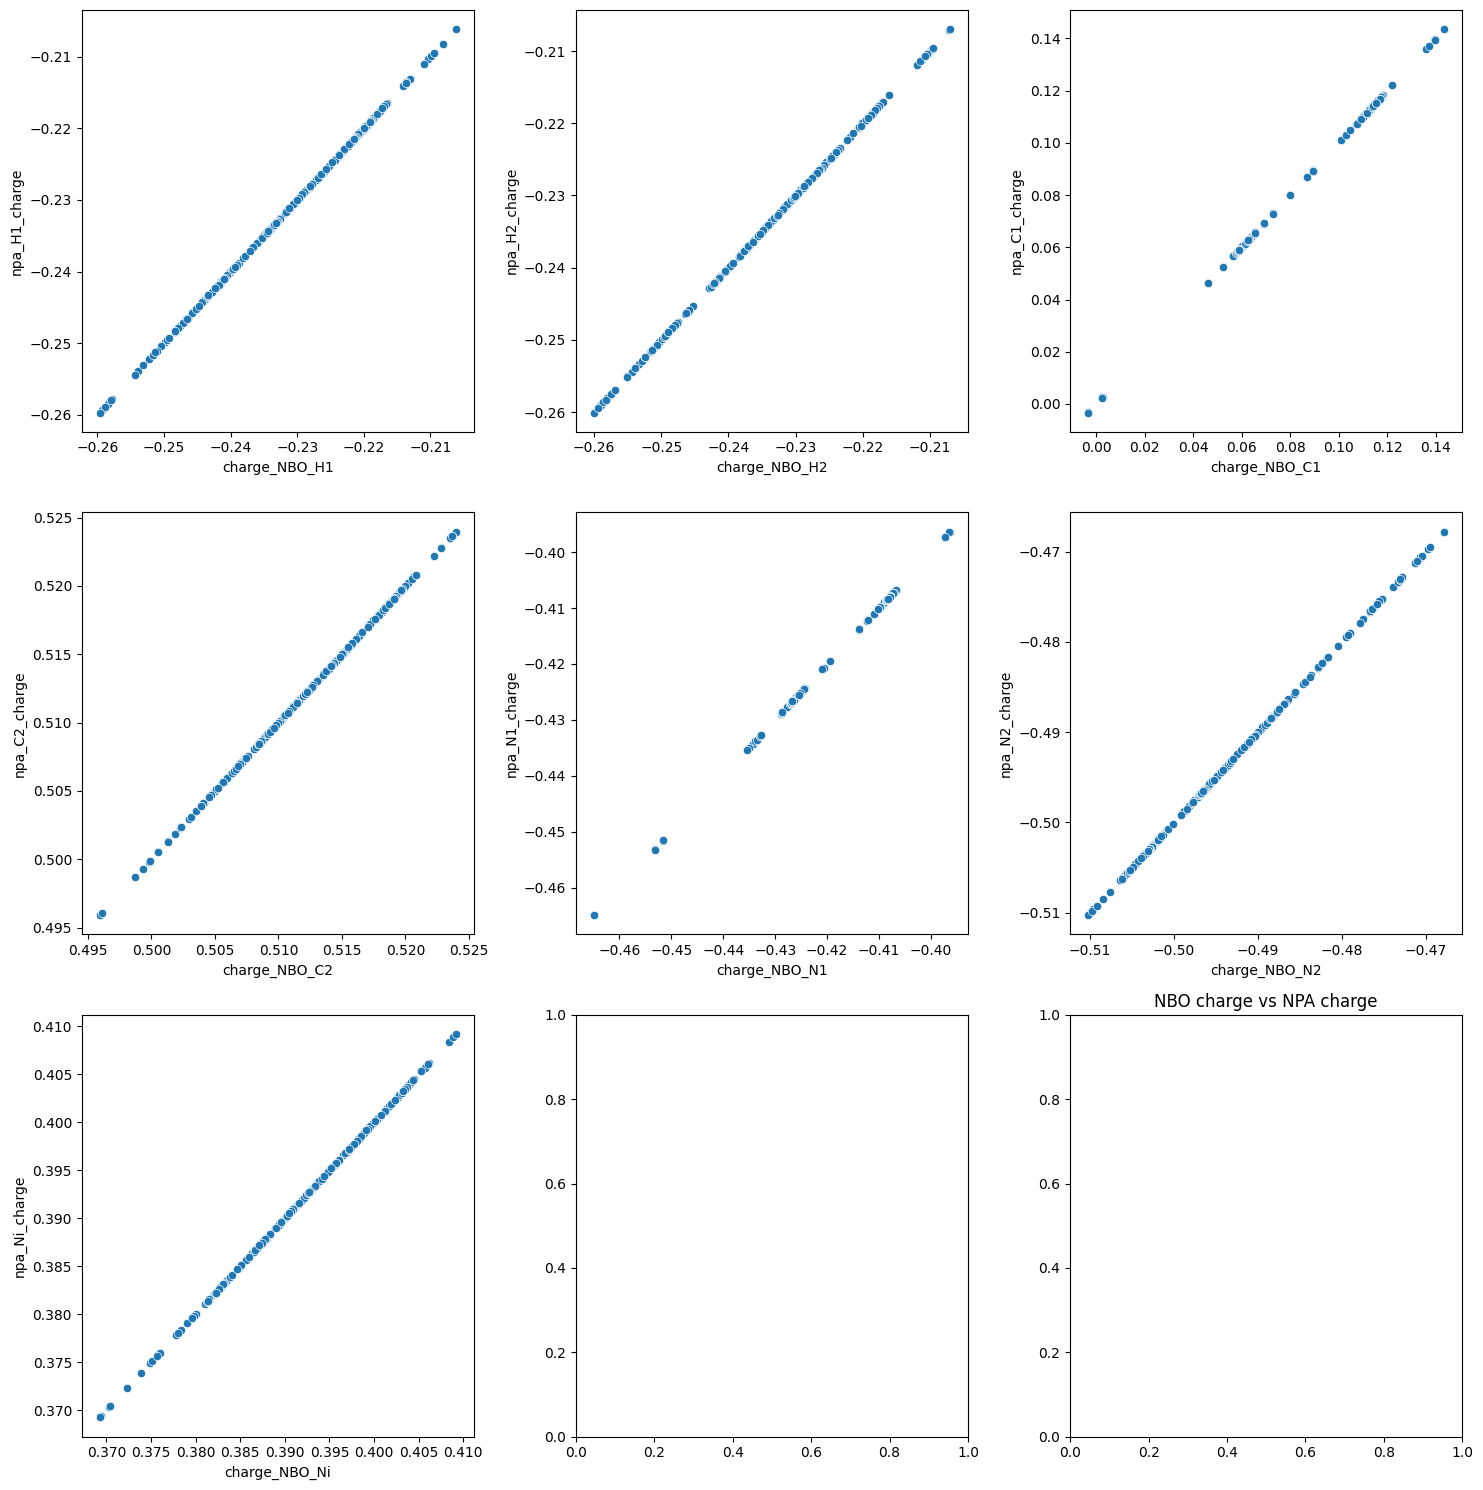

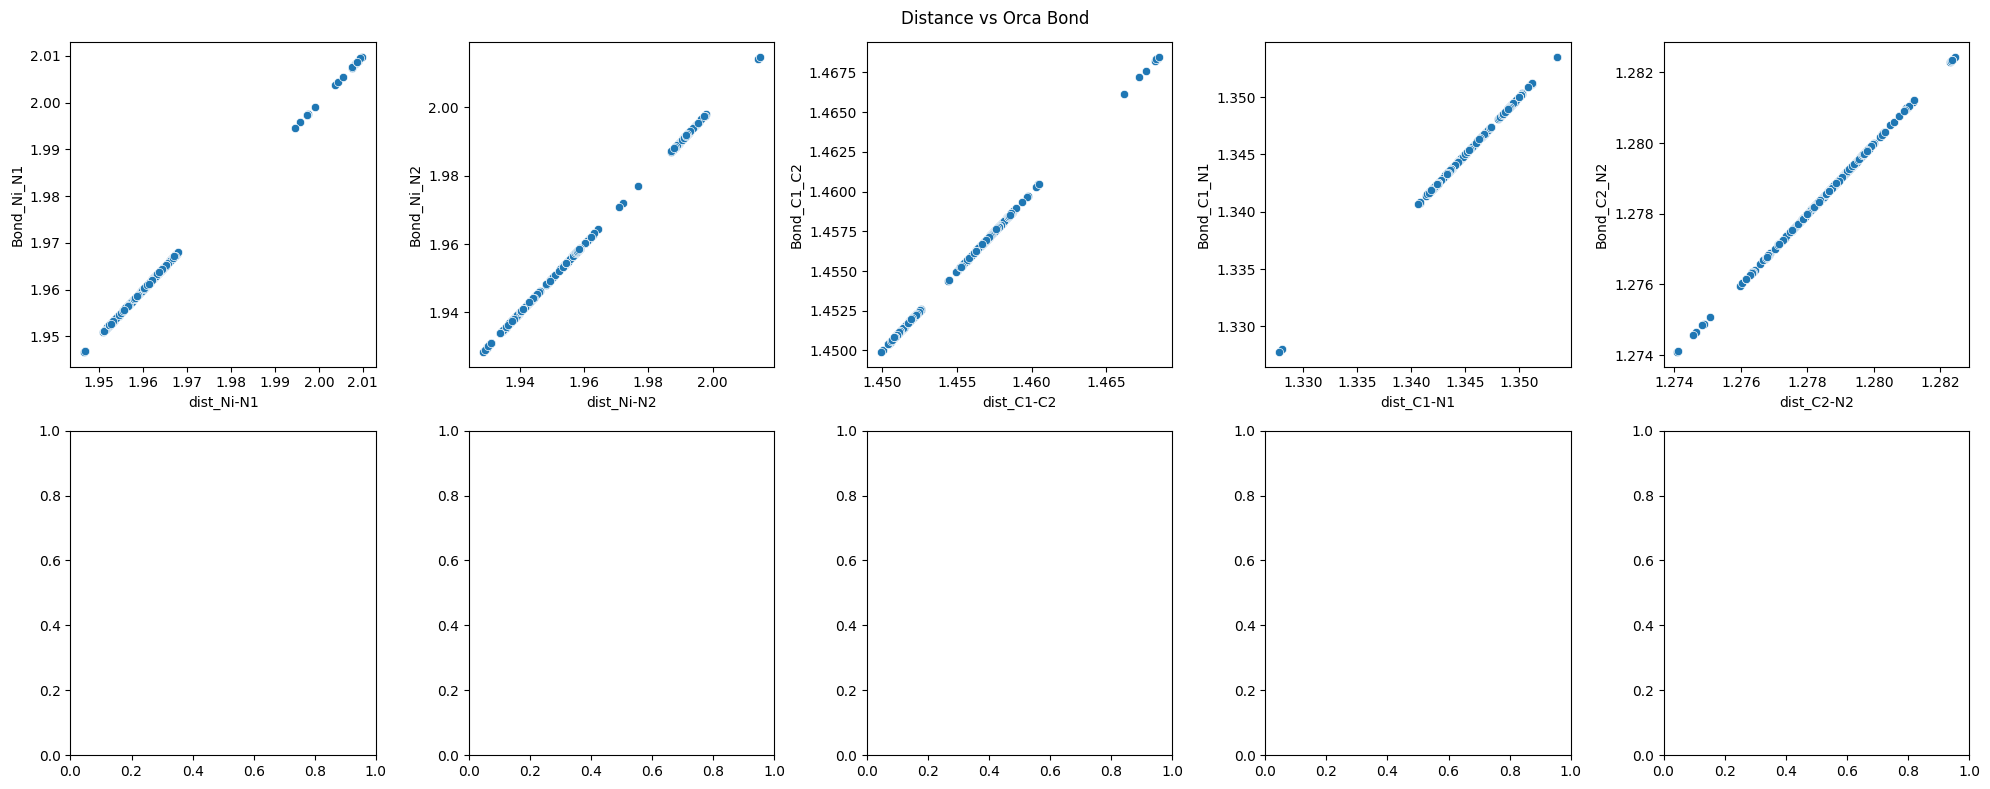

Could not find columns for C1-C2-N1


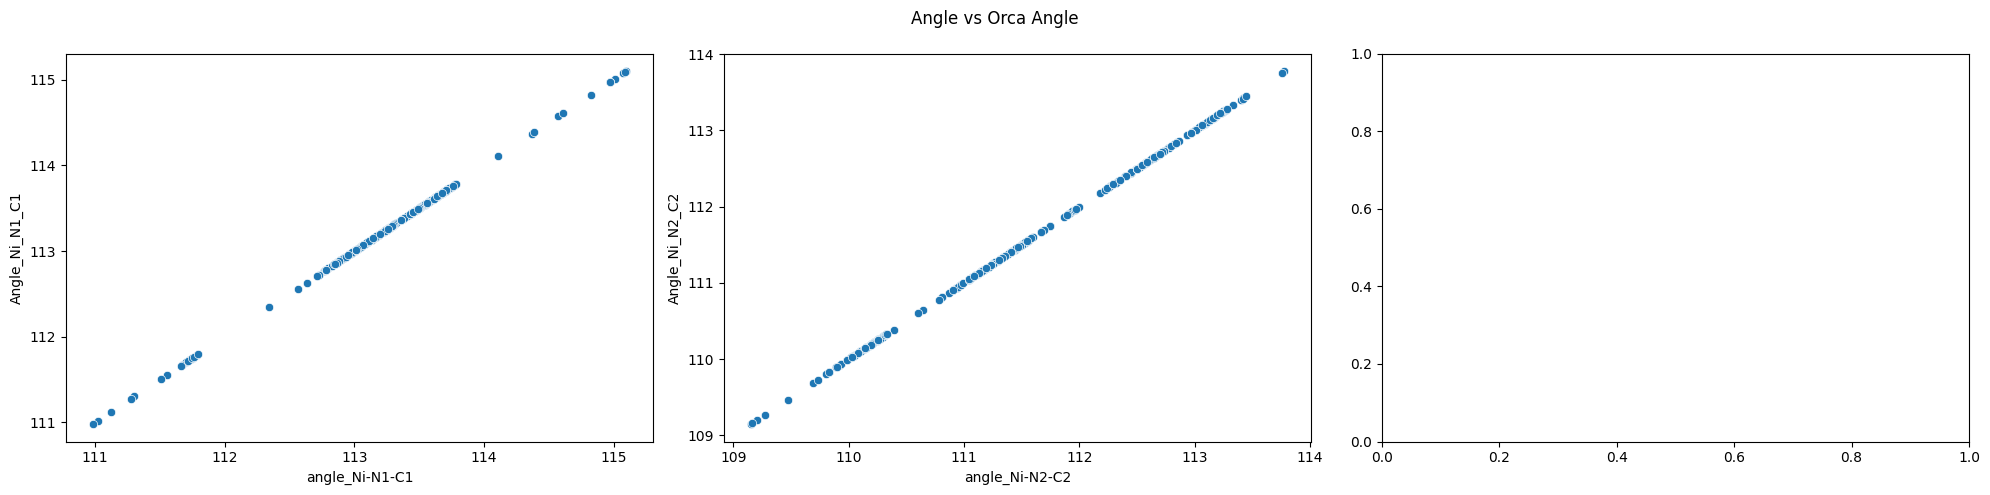

In [2]:
### Descripytor:
# charge_NBO_XX
# B1_X-X
# B5_X-X
# L_X-X
# loc_C5_X-X
# B1-B5_angle_X-X
# dist_X-X
# vib_freq_X-X
# vib_amp_X-X
# dipole
# dipole_x_X-X-X
# dipole_y_X-X-X
# dipole_z_X-X-X
# angle_X-X-X

### OrcaDescriptors:
# Angle_X_X_X
# Sterimol_X_X_Bmax
# Sterimol_X_X_Bmin
# Sterimol_X_X_L
# Bond_X_X
# npa_X_charge

X = ["H1", "H2", "C1", "C2", "N1", "N2", "Ni"]

fig, ax = plt.subplots(3, 3, figsize=(15, 15))
for x1 in enumerate(X):
    print(x1)
    sns.scatterplot(data=df, x=f"charge_NBO_{x1[1]}", y=f"npa_{x1[1]}_charge", ax=ax[x1[0] // 3, x1[0] % 3])

plt.title("NBO charge vs NPA charge")
plt.tight_layout()
plt.show()

B = [("Ni", "N1"), ("Ni", "N2"), ("C1", "C2"), ("C1", "N1"), ("C2", "N2")]
fig, ax = plt.subplots(2, 5, figsize=(20, 8))
for b1 in enumerate(B):
    if f"dist_{b1[1][0]}-{b1[1][1]}" in df.columns and f"Bond_{b1[1][0]}_{b1[1][1]}" in df.columns:
        sns.scatterplot(data=df, x=f"dist_{b1[1][0]}-{b1[1][1]}", y=f"Bond_{b1[1][0]}_{b1[1][1]}", ax=ax[b1[0] // 5, b1[0] % 5])
    elif f"dist_{b1[1][1]}-{b1[1][0]}" in df.columns and f"Bond_{b1[1][1]}_{b1[1][0]}" in df.columns:
        sns.scatterplot(data=df, x=f"dist_{b1[1][1]}-{b1[1][0]}", y=f"Bond_{b1[1][1]}_{b1[1][0]}", ax=ax[b1[0] // 5, b1[0] % 5])
    elif f"dist_{b1[1][0]}-{b1[1][1]}" in df.columns and f"Bond_{b1[1][1]}_{b1[1][0]}" in df.columns:
        sns.scatterplot(data=df, x=f"dist_{b1[1][0]}-{b1[1][1]}", y=f"Bond_{b1[1][1]}_{b1[1][0]}", ax=ax[b1[0] // 5, b1[0] % 5])
    elif f"dist_{b1[1][1]}-{b1[1][0]}" in df.columns and f"Bond_{b1[1][0]}_{b1[1][1]}" in df.columns:
        sns.scatterplot(data=df, x=f"dist_{b1[1][1]}-{b1[1][0]}", y=f"Bond_{b1[1][0]}_{b1[1][1]}", ax=ax[b1[0] // 5, b1[0] % 5])    
    else:
        print(f"Could not find columns for {b1[1][0]}-{b1[1][1]}")
plt.suptitle("Distance vs Orca Bond")
plt.tight_layout()
plt.show()

A = [("Ni", "N1", "C1"), ("Ni", "N2", "C2"), ("C1", "C2", "N1")]
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a1 in enumerate(A):
    if f"angle_{a1[1][0]}-{a1[1][1]}-{a1[1][2]}" in df.columns and f"Angle_{a1[1][0]}_{a1[1][1]}_{a1[1][2]}" in df.columns:
        sns.scatterplot(data=df, x=f"angle_{a1[1][0]}-{a1[1][1]}-{a1[1][2]}", y=f"Angle_{a1[1][0]}_{a1[1][1]}_{a1[1][2]}", ax=ax[a1[0]])
    elif f"angle_{a1[1][2]}-{a1[1][1]}-{a1[1][0]}" in df.columns and f"Angle_{a1[1][2]}_{a1[1][1]}_{a1[1][0]}" in df.columns:
        sns.scatterplot(data=df, x=f"angle_{a1[1][2]}-{a1[1][1]}-{a1[1][0]}", y=f"Angle_{a1[1][2]}_{a1[1][1]}_{a1[1][0]}", ax=ax[a1[0]])
    elif f"angle_{a1[1][1]}-{a1[1][2]}-{a1[1][0]}" in df.columns and f"Angle_{a1[1][1]}_{a1[1][2]}_{a1[1][0]}" in df.columns:
        sns.scatterplot(data=df, x=f"angle_{a1[1][1]}-{a1[1][2]}-{a1[1][0]}", y=f"Angle_{a1[1][1]}_{a1[1][2]}_{a1[1][0]}", ax=ax[a1[0]])
    elif f"angle_{a1[1][0]}-{a1[1][2]}-{a1[1][1]}" in df.columns and f"Angle_{a1[1][0]}_{a1[1][2]}_{a1[1][1]}" in df.columns:
        sns.scatterplot(data=df, x=f"angle_{a1[1][0]}-{a1[1][2]}-{a1[1][1]}", y=f"Angle_{a1[1][0]}_{a1[1][2]}_{a1[1][1]}", ax=ax[a1[0]])
    else:
        print(f"Could not find columns for {a1[1][0]}-{a1[1][1]}-{a1[1][2]}")
plt.suptitle("Angle vs Orca Angle")
plt.tight_layout()
plt.show()

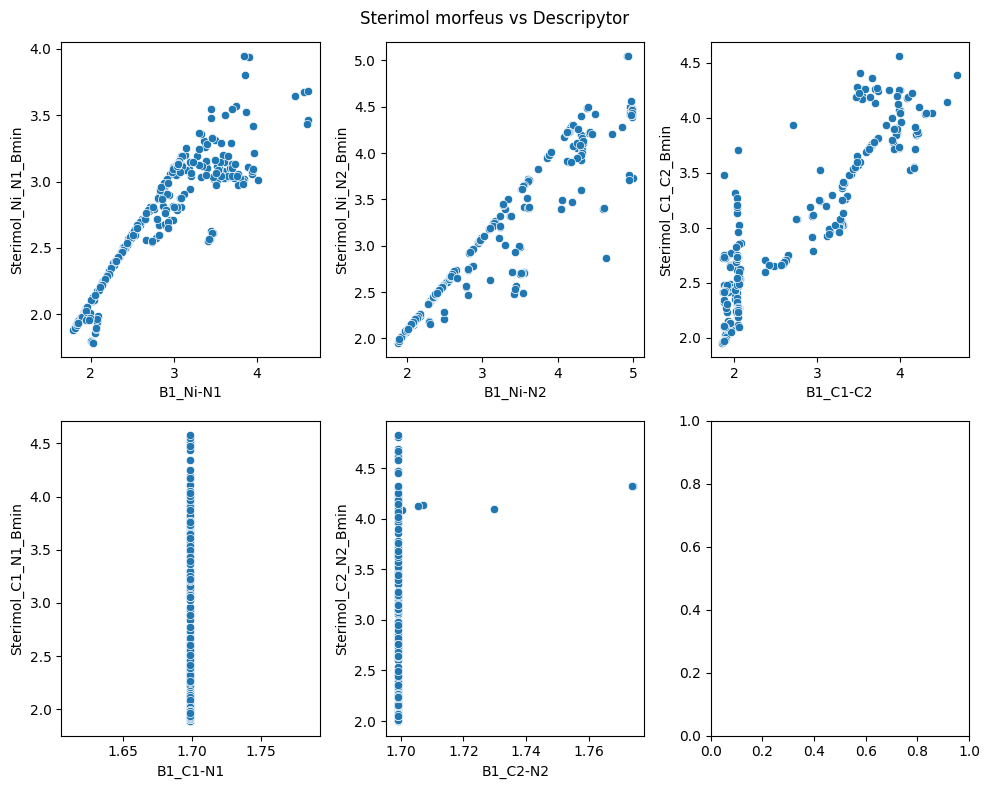

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(10, 8))
for b1 in enumerate(B):
    if f"B1_{b1[1][0]}-{b1[1][1]}" in df.columns and f"Sterimol_{b1[1][0]}_{b1[1][1]}_Bmin" in df.columns:
        sns.scatterplot(data=df, x=f"B1_{b1[1][0]}-{b1[1][1]}", y=f"Sterimol_{b1[1][0]}_{b1[1][1]}_Bmin", ax=ax[b1[0] // 3, b1[0] % 3])
    elif f"B1_{b1[1][1]}-{b1[1][0]}" in df.columns and f"Sterimol_{b1[1][1]}_{b1[1][0]}_Bmin" in df.columns:
        sns.scatterplot(data=df, x=f"B1_{b1[1][1]}-{b1[1][0]}", y=f"Sterimol_{b1[1][1]}_{b1[1][0]}_Bmin", ax=ax[b1[0] // 3, b1[0] % 3])
    elif f"B1_{b1[1][0]}-{b1[1][1]}" in df.columns and f"Sterimol_{b1[1][1]}_{b1[1][0]}_Bmin" in df.columns:
        sns.scatterplot(data=df, x=f"B1_{b1[1][0]}-{b1[1][1]}", y=f"Sterimol_{b1[1][1]}_{b1[1][0]}_Bmin", ax=ax[b1[0] // 3, b1[0] % 3])
    elif f"B1_{b1[1][1]}-{b1[1][0]}" in df.columns and f"Sterimol_{b1[1][0]}_{b1[1][1]}_Bmin" in df.columns:
        sns.scatterplot(data=df, x=f"B1_{b1[1][1]}-{b1[1][0]}", y=f"Sterimol_{b1[1][0]}_{b1[1][1]}_Bmin", ax=ax[b1[0] // 3, b1[0] % 3])
    else:
        print(f"Could not find columns for {b1[1][0]}-{b1[1][1]}")
plt.suptitle("Sterimol morfeus vs Descripytor")
plt.tight_layout()
plt.show()

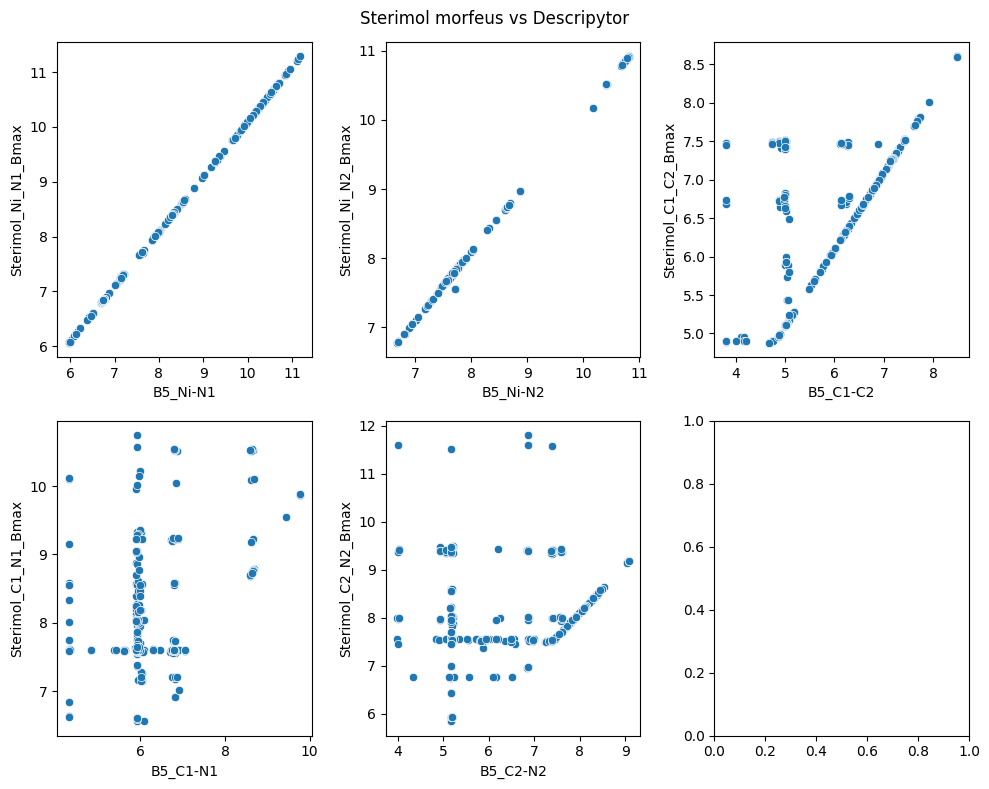

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(10, 8))
for b1 in enumerate(B):
    if f"B5_{b1[1][0]}-{b1[1][1]}" in df.columns and f"Sterimol_{b1[1][0]}_{b1[1][1]}_Bmax" in df.columns:
        sns.scatterplot(data=df, x=f"B5_{b1[1][0]}-{b1[1][1]}", y=f"Sterimol_{b1[1][0]}_{b1[1][1]}_Bmax", ax=ax[b1[0] // 3, b1[0] % 3])
    elif f"B5_{b1[1][1]}-{b1[1][0]}" in df.columns and f"Sterimol_{b1[1][1]}_{b1[1][0]}_Bmax" in df.columns:
        sns.scatterplot(data=df, x=f"B5_{b1[1][1]}-{b1[1][0]}", y=f"Sterimol_{b1[1][1]}_{b1[1][0]}_Bmax", ax=ax[b1[0] // 3, b1[0] % 3])
    elif f"B5_{b1[1][0]}-{b1[1][1]}" in df.columns and f"Sterimol_{b1[1][1]}_{b1[1][0]}_Bmax" in df.columns:
        sns.scatterplot(data=df, x=f"B5_{b1[1][0]}-{b1[1][1]}", y=f"Sterimol_{b1[1][1]}_{b1[1][0]}_Bmax", ax=ax[b1[0] // 3, b1[0] % 3])
    elif f"B5_{b1[1][1]}-{b1[1][0]}" in df.columns and f"Sterimol_{b1[1][0]}_{b1[1][1]}_Bmax" in df.columns:
        sns.scatterplot(data=df, x=f"B5_{b1[1][1]}-{b1[1][0]}", y=f"Sterimol_{b1[1][0]}_{b1[1][1]}_Bmax", ax=ax[b1[0] // 3, b1[0] % 3])
    else:
        print(f"Could not find columns for {b1[1][0]}-{b1[1][1]}")
plt.suptitle("Sterimol morfeus vs Descripytor")
plt.tight_layout()
plt.show()

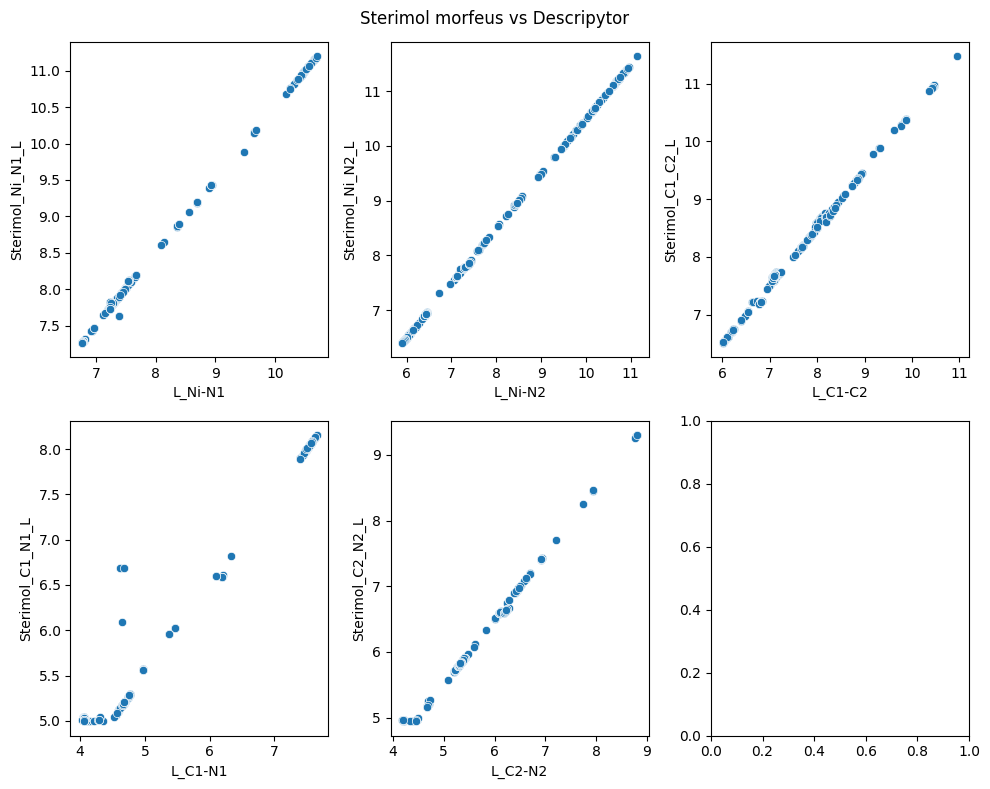

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(10, 8))
for b1 in enumerate(B):
    if f"L_{b1[1][0]}-{b1[1][1]}" in df.columns and f"Sterimol_{b1[1][0]}_{b1[1][1]}_L" in df.columns:
        sns.scatterplot(data=df, x=f"L_{b1[1][0]}-{b1[1][1]}", y=f"Sterimol_{b1[1][0]}_{b1[1][1]}_L", ax=ax[b1[0] // 3, b1[0] % 3])
    elif f"L_{b1[1][1]}-{b1[1][0]}" in df.columns and f"Sterimol_{b1[1][1]}_{b1[1][0]}_L" in df.columns:
        sns.scatterplot(data=df, x=f"L_{b1[1][1]}-{b1[1][0]}", y=f"Sterimol_{b1[1][1]}_{b1[1][0]}_L", ax=ax[b1[0] // 3, b1[0] % 3])
    elif f"L_{b1[1][0]}-{b1[1][1]}" in df.columns and f"Sterimol_{b1[1][1]}_{b1[1][0]}_L" in df.columns:
        sns.scatterplot(data=df, x=f"L_{b1[1][0]}-{b1[1][1]}", y=f"Sterimol_{b1[1][1]}_{b1[1][0]}_L", ax=ax[b1[0] // 3, b1[0] % 3])
    elif f"L_{b1[1][1]}-{b1[1][0]}" in df.columns and f"Sterimol_{b1[1][0]}_{b1[1][1]}_L" in df.columns:
        sns.scatterplot(data=df, x=f"L_{b1[1][1]}-{b1[1][0]}", y=f"Sterimol_{b1[1][0]}_{b1[1][1]}_L", ax=ax[b1[0] // 3, b1[0] % 3])
    else:
        print(f"Could not find columns for {b1[1][0]}-{b1[1][1]}")
plt.suptitle("Sterimol morfeus vs Descripytor")
plt.tight_layout()
plt.show()

In [6]:
df_small = df[df.inchi == "AATATIAROAAKIN-SNVBAGLBSA-N"]
df_small

,path,xyz_name,ligand_type,inchi,SCF_energy,smiles,ligand_class,feather_path,SASA,SASA_Volume,...,dipole_x_Ni-N2-N1,dipole_y_Ni-N2-N1,dipole_z_Ni-N2-N1,angle_H2-Ni-H1,angle_Ni-N1-C1,angle_Ni-N2-C2,angle_N1-C1-C2,angle_N2-C2-C1,angle_N1-Ni-N2,angle_C1-Ni-C2
0,orca_descriptors/DATA/LNiH2_library_001_to_dow...,optimization,core_5,AATATIAROAAKIN-SNVBAGLBSA-N,-2497.275318,[H]C1=C(C(F)(F)F)C([H])=C([H])C(=C2N[C@@]([H])...,pyox,DATA/LNiH2_library_001_to_download_2026_03_24/...,478.627807,774.188519,...,0.503153,2.761978,0.378164,81.079588,113.298488,111.525251,111.740677,119.600391,82.847527,30.800116
1,orca_descriptors/DATA/LNiH2_library_001_to_dow...,optimization,core_5,AATATIAROAAKIN-SNVBAGLBSA-N,-2497.275345,[H]C1=C(C(F)(F)F)C([H])=C([H])C(=C2N[C@@]([H])...,pyox,DATA/LNiH2_library_001_to_download_2026_03_24/...,478.797803,774.604492,...,0.503899,2.757717,0.375512,81.055124,113.315642,111.511015,111.763413,119.625508,82.875770,30.800174


/var/folders/_g/6jml0x190szd85mnhhx81ydm0000gn/T/ipykernel_22548/3737135306.py:10: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax[b1[0] // 3, b1[0] % 3].set_xlim(min_val - 0.1*(max_val - min_val), max_val + 0.1*(max_val - min_val))
/var/folders/_g/6jml0x190szd85mnhhx81ydm0000gn/T/ipykernel_22548/3737135306.py:10: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax[b1[0] // 3, b1[0] % 3].set_xlim(min_val - 0.1*(max_val - min_val), max_val + 0.1*(max_val - min_val))


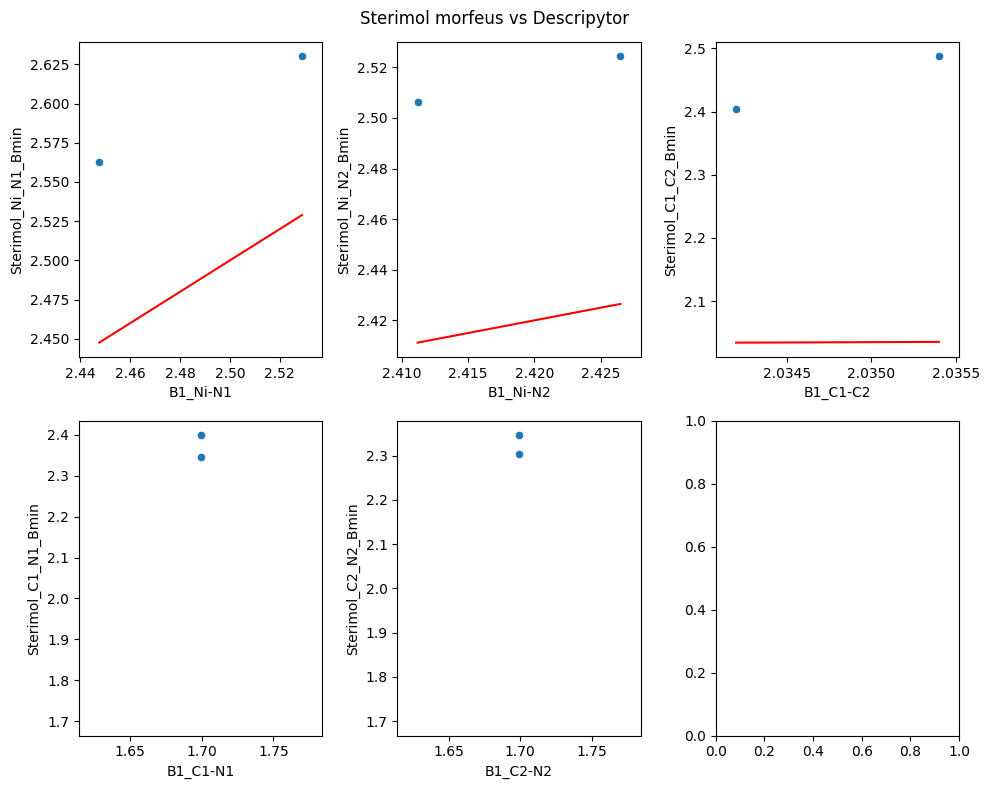

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(10, 8))
for b1 in enumerate(B):
    if f"B1_{b1[1][0]}-{b1[1][1]}" in df_small.columns and f"Sterimol_{b1[1][0]}_{b1[1][1]}_Bmin" in df_small.columns:
        sns.scatterplot(data=df_small, x=f"B1_{b1[1][0]}-{b1[1][1]}", y=f"Sterimol_{b1[1][0]}_{b1[1][1]}_Bmin", ax=ax[b1[0] // 3, b1[0] % 3])
        min_val = min(df_small[f"B1_{b1[1][0]}-{b1[1][1]}"].min(), df_small[f"B1_{b1[1][0]}-{b1[1][1]}"].min())
        max_val = max(df_small[f"B1_{b1[1][0]}-{b1[1][1]}"].max(), df_small[f"B1_{b1[1][0]}-{b1[1][1]}"].max())
        ax[b1[0] // 3, b1[0] % 3].plot([min_val, max_val],
                                        [min_val, max_val],
                                        color="red")
        ax[b1[0] // 3, b1[0] % 3].set_xlim(min_val - 0.1*(max_val - min_val), max_val + 0.1*(max_val - min_val))
    elif f"B1_{b1[1][1]}-{b1[1][0]}" in df_small.columns and f"Sterimol_{b1[1][1]}_{b1[1][0]}_Bmin" in df_small.columns:
        sns.scatterplot(data=df_small, x=f"B1_{b1[1][1]}-{b1[1][0]}", y=f"Sterimol_{b1[1][1]}_{b1[1][0]}_Bmin", ax=ax[b1[0] // 3, b1[0] % 3])
        min_val = min(df_small[f"B1_{b1[1][1]}-{b1[1][0]}"].min(), df_small[f"B1_{b1[1][1]}-{b1[1][0]}"].min())
        max_val = max(df_small[f"B1_{b1[1][1]}-{b1[1][0]}"].max(), df_small[f"B1_{b1[1][1]}-{b1[1][0]}"].max())
        ax[b1[0] // 3, b1[0] % 3].plot([min_val, max_val],
                                        [min_val, max_val],
                                        color="red")
        ax[b1[0] // 3, b1[0] % 3].set_xlim(min_val - 0.1*(max_val - min_val), max_val + 0.1*(max_val - min_val))
    elif f"B1_{b1[1][0]}-{b1[1][1]}" in df_small.columns and f"Sterimol_{b1[1][1]}_{b1[1][0]}_Bmin" in df_small.columns:
        sns.scatterplot(data=df_small, x=f"B1_{b1[1][0]}-{b1[1][1]}", y=f"Sterimol_{b1[1][1]}_{b1[1][0]}_Bmin", ax=ax[b1[0] // 3, b1[0] % 3])
        min_val = min(df_small[f"B1_{b1[1][0]}-{b1[1][1]}"].min(), df_small[f"B1_{b1[1][0]}-{b1[1][1]}"].min())
        max_val = max(df_small[f"B1_{b1[1][0]}-{b1[1][1]}"].max(), df_small[f"B1_{b1[1][0]}-{b1[1][1]}"].max())
        ax[b1[0] // 3, b1[0] % 3].plot([min_val, max_val],
                                        [min_val, max_val],
                                        color="red")
        ax[b1[0] // 3, b1[0] % 3].set_xlim(min_val - 0.1*(max_val - min_val), max_val + 0.1*(max_val - min_val))   


    else:
        print(f"Could not find columns for {b1[1][0]}-{b1[1][1]}")
plt.suptitle("Sterimol morfeus vs Descripytor")
plt.tight_layout()
plt.show()